# Zero shot and Few shot learning for text classification

In this notebook we'll explore the use of LangChain for **few shot learning** in the context of text classification.

**Few shot learning** is a form of machine learning where a model is taught to perform a particular task, such as classification or named entity recognition, by being provided with a few examples only, instead of a large training set, as is the case in 'traditional' machine learning tasks.

As any other task based on large languge models (LLMs), few shot learning relies on the use of appropriate prompts. LangChain offers prompt template classes specifically built for few shot learning, which we will use to classify a set of software requirements into functional and non-functional.

There is also **zero-shot learning**, where the model is asked to performe a specific task without any examples being given, only guidance / instruction in natural language (prompt). Still, it is often recommended to provide the model with at least one example.


We start by installing the required python packages...

In [1]:
!pip -q install langchain langchain_community langchain_groq

In [2]:
# adding packages for OpenAI's models in case we run out of free access to Groq
# !pip install -q openai langchain-openai

To select examples for few-shot learning, we will use [`faiss-cpu`](https://pypi.org/project/faiss-cpu/), a python implentation of the Facebook's [FAISS](https://github.com/facebookresearch/faiss) library for efficient similarity search and clustering of text embeddings. The reason we need similaroty search is that we want to select examples similar to the user's input (i.e., the instance to be classified).

In [3]:
!pip -q install faiss-cpu

Finally, we need libraries for the embeddings model we will use to create vector representation of examples for few-shot learning (such embeddings-based representation of examples is required for performing search of relevant examples, as will be explained later on)


In [4]:
!pip -q install sentence_transformers FlagEmbedding langchain-huggingface

In [5]:
import os
from google.colab import userdata

from langchain_groq import ChatGroq

from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser, JsonOutputParser

SEED = 9

### Instantiate an LLM chat model

As before, we will use Groq API to access `gpt-oss-20b` model. More precisely, we will leverage [LangChain's integration with Groq API](https://python.langchain.com/docs/integrations/chat/groq/), which further simplifies instantiation of LLMs that Groq offers.

To use Groq services, we need to load Groq API key into the current application environment (as shown below).

For more details about `gpt-oss-20b` model and access to it via Groq API, see [the LangChain Intro notebook](https://github.com/jeljov/NAP2026/blob/main/llms/LangChain_Intro_2026.ipynb).

In [6]:
os.environ["GROQ_API_KEY"] = userdata.get('GROQ_API_KEY')

llm = ChatGroq(model="openai/gpt-oss-20b",
               temperature=0.0,
               model_kwargs={'seed':SEED})

The code below is instantiating an OpenAIChat model in case we run out of free tokens on Groq

In [7]:
# from langchain_openai import ChatOpenAI

# os.environ['OPENAI_API_KEY'] = userdata.get('OPENAI_API_KEY')

# llm = ChatOpenAI(model='gpt-4o-mini', temperature=0.0, seed=SEED)

## Zero shot learning through prompting

Let's see an example where we will try to instruct an LLM to classify software requirements into functional and non-fuctional.

We start by checking if the model is 'aware' of these two main categories of software requirements:

In [8]:
system_message = """
You are a well established software engineer with a lot of experience in gathering and managing software requirements.
You assist the user by answering their questions about software requirements in a clear and concise manner.
Restrict your answer to one paragraph only.
"""

user_message = "What are {req_type} requirements?"

initial_prompt = ChatPromptTemplate.from_messages([
    ('system', system_message),
    ('human', user_message),
])

simple_chain = initial_prompt | llm | StrOutputParser()

In [9]:
resp_functional_req = simple_chain.invoke('functional')
print(resp_functional_req)

Functional requirements describe the specific behaviors, actions, and services that a software system must provide to satisfy user needs and business goals; they outline what the system should do, such as processing data, generating reports, handling transactions, or interacting with other systems, and are typically expressed in terms of inputs, outputs, and the conditions under which the system operates.


We will add a simple utility function that wraps the text so that it is easier to read the model's output:

In [10]:
def wrap_and_print(text, width=100):
  import textwrap
  wrapped_text = textwrap.fill(text, width=width)
  print(wrapped_text +'\n')

In [11]:
wrap_and_print(resp_functional_req)

Functional requirements describe the specific behaviors, actions, and services that a software
system must provide to satisfy user needs and business goals; they outline what the system should
do, such as processing data, generating reports, handling transactions, or interacting with other
systems, and are typically expressed in terms of inputs, outputs, and the conditions under which the
system operates.



In [12]:
resp_nonfunctional_req = simple_chain.invoke('non-functional')
wrap_and_print(resp_nonfunctional_req)

Non‑functional requirements describe how a system should behave rather than what it should do; they
specify attributes such as performance, scalability, reliability, security, usability,
maintainability, and compliance. These constraints guide design decisions, influence architecture,
and are critical for evaluating system quality, ensuring it meets user expectations and operational
standards. They are typically measured, testable, and often expressed as thresholds or criteria
(e.g., response time < 200 ms, uptime 99.9 %, encryption at rest).



Since the LLM is quite knowledgeable about software requirements, we may first try classification of requirements into functional and non-functional via **zero-shot learning**:

In [13]:
zero_shot_system_msg = """
You are an experienced software engineer with expertise in requirements engineering.
Please help the user classify software requirements into functional and non-functional.
The user will give you a list of software requirements, each requirement starting in a new line.
Classify each requirement in the user's list into functional ("Functional") or non-functional ("Non-functional") categories.
Think through each requirement in the user's list before classifying it.
If you don't know how to classify a requirement, assign to it the "None" label.
Return your response as a JSON list of tuples, where the first element in the tuple is the text of a requirement from the user's list, while the second elements is the category assigned to that requirement (or "None" if you do no know how to classify it).
Your response should include only this JSON list and nothing else.
"""

zero_shot_user_msg="Software requirements to classify:\n{requirements}"

zero_shot_template = ChatPromptTemplate.from_messages([
    ('system', zero_shot_system_msg),
    ('human', zero_shot_user_msg),
])

zero_shot_simple_chain = zero_shot_template | llm | JsonOutputParser()

As an initial set of data for testing the zero-shot prompting, we'll use a small set of requirements in the form of user stories, for a (imaginary) music recommender mobile app:

In [14]:
sample_requirements_list = [
    "I want to sign up with my email and password so I can access the app's features.",
    "I want to create, name, and modify a custom playlist so I can organize my favorite tracks.",
    "I want the music recommendation list to load in less than two seconds so I don't have to wait.",
    "I expect all my listening history and personal data to be securely encrypted so my information is protected.",
    "I want to be able to save a recommended song for offline playback so I can listen to it without an internet connection.",
    "I need the app to be available 99.9% of the time so I can reliably listen to music during my travels.",
    "I need the app's interface to look and behave consistently across all screens so it's intuitive and easy to use.",
    "I want to be able to search for music by typing an artist name, song title, or genre so I can quickly find what I'm looking for.",
    "I need the app to continue playing music if I briefly lose my cellular connection so my listening experience isn't interrupted.",
    "I want the app to use no more than 100MB of storage for cached data so my phone doesn't run out of space.",
    "I want to be able to 'Like' or 'Dislike' a recommended song so the system can improve future recommendations."
]

sample_requrements_str = "- " + "\n- ".join(sample_requirements_list)

In [15]:
print(zero_shot_template.format(requirements = sample_requrements_str))

System: 
You are an experienced software engineer with expertise in requirements engineering.
Please help the user classify software requirements into functional and non-functional.
The user will give you a list of software requirements, each requirement starting in a new line.
Classify each requirement in the user's list into functional ("Functional") or non-functional ("Non-functional") categories.
Think through each requirement in the user's list before classifying it.
If you don't know how to classify a requirement, assign to it the "None" label.
Return your response as a JSON list of tuples, where the first element in the tuple is the text of a requirement from the user's list, while the second elements is the category assigned to that requirement (or "None" if you do no know how to classify it).
Your response should include only this JSON list and nothing else.

Human: Software requirements to classify:
- I want to sign up with my email and password so I can access the app's feat

In [16]:
zero_shot_classes = zero_shot_simple_chain.invoke(sample_requrements_str)

In [17]:
type(zero_shot_classes[0])

list

In [18]:
for i, classified_req in enumerate(zero_shot_classes):
  req, cls = classified_req
  print(f"{i+1}. {req}: {cls.upper()}")

1. I want to sign up with my email and password so I can access the app's features.: FUNCTIONAL
2. I want to create, name, and modify a custom playlist so I can organize my favorite tracks.: FUNCTIONAL
3. I want the music recommendation list to load in less than two seconds so I don't have to wait.: NON-FUNCTIONAL
4. I expect all my listening history and personal data to be securely encrypted so my information is protected.: NON-FUNCTIONAL
5. I want to be able to save a recommended song for offline playback so I can listen to it without an internet connection.: FUNCTIONAL
6. I need the app to be available 99.9% of the time so I can reliably listen to music during my travels.: NON-FUNCTIONAL
7. I need the app's interface to look and behave consistently across all screens so it's intuitive and easy to use.: NON-FUNCTIONAL
8. I want to be able to search for music by typing an artist name, song title, or genre so I can quickly find what I'm looking for.: FUNCTIONAL
9. I need the app to con

This worked well, but as few-shot generally performs better than zero-shot and this was just a tiny sample, we'll next explore few-shot learning.

## Few shot learning

The idea behind **few shot learning** is to provide an LLM with some additional knowledge and / or instruction how to use the knowledge it has, to be able to perform a particular task.

Note: knowledge that an LLM 'develops' through training (both pre-training and instruction and preference tuning) is often referred to as **parametric knowledge**, whereas any additional knowledge and / or instruction it receives later, during the actual use is known as **contextual knowledge**.

In case of Chat LLMs, this *contextual knowledge*, comes in the form of a few pairs of interactions between the user and the chatbot, serving as examples of what we expect the model to do after receiving an input from the user. It has been shown that in large majority of cases, with only a few examples (3-4) and sometimes even only one example, a model can be well instructed for almost any specific task.

A nice quick intro to few shot learning (through prompting) is given in [this](https://youtu.be/JSBjj09xJeM?si=DJwLOeFHX7KOTGq2) short (5min) lecture from U. of Texas.

One of the main challenges in few-shot learning is the selection of examples to give to the model to learn from, as these should be sufficiently represenative of the user input. LangChain offers support for example selection, as we'll explore next.  

### LangChain's support for few shot learning


To learn about dynamic few-shot prompting (i.e., few-shot prompting with dynamic example selection) , we will use a dataset of software requirements with human-assigned functional / non-functional labels. The dataset orginates from the "[Software requirements dataset](https://www.kaggle.com/datasets/iamvaibhav100/software-requirements-dataset)" available from Kaggle.com

We will start by loading the dataset (stored localy in the `software_requirements_processed.csv` file) and selecting a small sample of requirements to serve as examples for few shot learning, whereas the remaining ones will be used for evaluation purposes.

In [19]:
from google.colab import files

data_file = files.upload()

Saving software_requirements_processed.csv to software_requirements_processed (1).csv


In [20]:
data_file.keys()

dict_keys(['software_requirements_processed (1).csv'])

The uploaded object is a dictionary having the filename and content as it’s key-value pair. So, we can extract the file name and read in the file content using pandas (to have it in the pandas DataFrame format)

In [21]:
import pandas as pd

file_name = list(data_file.keys())[0]
req_data = pd.read_csv(file_name)
req_data.shape

(977, 3)

In [22]:
req_data.head(10)

,Type,Requirement,Category
0,PE,The system shall refresh the display every 60 ...,Non-functional
1,LF,The application shall match the color of the s...,Non-functional
2,US,If projected the data must be readable. On ...,Non-functional
3,A,The product shall be available during normal ...,Non-functional
4,US,If projected the data must be understandable...,Non-functional
5,SE,The product shall ensure that it can only be a...,Non-functional
6,US,The product shall be intuitive and self-explan...,Non-functional
7,PE,The product shall respond fast to keep up-to-d...,Non-functional
8,F,The system shall have a MDI form that allows f...,Functional
9,F,The system shall display Events in a vertical ...,Functional


We can examine the distribution of functional / non-functional requirements in this dataset:

In [23]:
req_data.Category.value_counts(normalize=True)

,proportion
Category,
Functional,0.533265
Non-functional,0.466735


Next, we take a small random sample - say 100 requirements - from which we will select (a much smaller subset of) examples for few shot learning

In [24]:
req_ex_sample = req_data.sample(100, random_state=SEED)
req_ex_sample.Category.value_counts()

,count
Category,
Functional,52
Non-functional,48


In [25]:
req_ex_sample.head()

,Type,Requirement,Category
936,FR,"In this case, the user can add as many as item...",Functional
2,US,If projected the data must be readable. On ...,Non-functional
439,US,A new user shall be able to navigate through t...,Non-functional
499,US,The system shall be intuitive to the Program A...,Non-functional
922,FR,"In this case, user enters his/her username or ...",Functional


This random set of labelled requirements need to be turned into a list of examples, where each example is presented as a dictionary of two items: a requirement and its corresponding type (functional / non-functional), as exemplified below:

```
examples = [
    {
      "Requirement": "This is a placeholder for a real software requirement",
      "Category": "Functional"
    },
    {
      "Requirement": "This is a placeholder for a real software requirement",
      "Category": "Non-functional"
    },
    #....
]
```
To create such a list easily, we change the name of the data frame columns and transform the data frame into a list of dictionaries:

In [26]:
req_ex_list = req_ex_sample[['Requirement','Category']].to_dict('records')
display(len(req_ex_list))
display(req_ex_list[:5])

100

[{'Requirement': 'In this case, the user can add as many as items he/she wants. The user can also set the price, set the amount, upload pictures of the item and add details of the item.',
  'Category': 'Functional'},
 {'Requirement': ' If projected  the data must be readable.  On a 10x10 projection screen  90% of viewers must be able to read Event / Activity data from a viewing distance of 30',
  'Category': 'Non-functional'},
 {'Requirement': 'A new user shall be able to navigate through the league and team pages within 30 seconds of reaching the start-up page.',
  'Category': 'Non-functional'},
 {'Requirement': 'The system shall be intuitive to the Program Administrators/Nursing Staff Members.',
  'Category': 'Non-functional'},
 {'Requirement': 'In this case, user enters his/her username or email and his/her password and logs in the system.',
  'Category': 'Functional'}]

To select a subset of examples to be used for few shot classification of a user's input (requirement), we will use LangChain's `SemanticSimilarityExampleSelector`, an example selector that selects examples so that they are highly similar to the user input.

To compute similarity between the user's input and the examples, we need to represent the inputs and the examples in a numerical format, suitable for (similarity) computation. To that end, we will use **text embeddings** as currently the most widely used approach for representing textual content.  

Specifically, we will use the [bge-large-en-v1.5](https://huggingface.co/BAAI/bge-large-en-v1.5) open source model for creating text embeddings. It was selected due to its small size and good performance. It was developed by the Beijing Academy of AI and as other open source language models, it is available from the [HuggingFace Hub](https://huggingface.co/models).

You may want to explore the [embedding models leaderboard at HuggingFace](https://huggingface.co/spaces/mteb/leaderboard) to find alternative models you may want to try out.

Note that LangChain directly supports large number of embedding models; for a list of supported models and instructions (code examples) how to use them, go to [Integrations > Embedding models](https://docs.langchain.com/oss/python/integrations/embeddings) in LangChain documentation.

A reminder: To access a model hosted at HuggingFace Hub, you'll need a HuggingFace (HF) access token. To obtain such a token, you should first create an account at [HuggingFace.co](https://huggingface.co/). Then, click on your profile in the top-right corner, then *Settings*, then *Access Tokens*, then *New Token*, set *Role* to *write* and *Generate*.

In [27]:
from langchain_huggingface import HuggingFaceEmbeddings

os.environ["HF_TOKEN"] = userdata.get('HF_TOKEN')

model_name = "BAAI/bge-large-en-v1.5"

bge_embeddings = HuggingFaceEmbeddings(
  model_name=model_name,
  model_kwargs={'device': 'cpu'}, # tells it to use CPU; alternative is 'cuda' to run on GPU
  encode_kwargs={'normalize_embeddings': True} # normalising embeddings as that is required for the computation of cosine similarity (which will be used later)
)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Next, we instantiate the `SemanticSimilarityExampleSelector`, with the BGE embeddings model and [FAISS](https://engineering.fb.com/2017/03/29/data-infrastructure/faiss-a-library-for-efficient-similarity-search/) as the vectors store.

FAISS is an in-memory vector store, which allows for quick search of (embedded / vectorised) documents based on different similarity measures

In [28]:
from langchain_core.example_selectors.semantic_similarity import SemanticSimilarityExampleSelector
from langchain_community.vectorstores.faiss import FAISS

example_selector = SemanticSimilarityExampleSelector.from_examples(
    # the list of examples available to select from
    examples=req_ex_list,
    # the embeddings model to be used to represent the examples, so that their semantic similarity can be computed
    embeddings=bge_embeddings,
    # The VectorStore class that is used to store the embeddings and do a similarity search over
    vectorstore_cls=FAISS,
    # The number of examples to select
    k=3
)

/tmp/ipykernel_29244/669637305.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores.faiss import FAISS


We can first try it out

In [29]:
sample_input = {"Requirement": "A new user shall be able to navigate through the league and team pages within 30 seconds of reaching the start-up page."}

selected_examples = example_selector.select_examples(sample_input)

for ex in selected_examples:
  print(f"Requirement: \"{ex['Requirement']}\": {ex['Category']}")

Requirement: "A new user shall be able to navigate through the league and team pages within 30 seconds of reaching the start-up page.": Non-functional
Requirement: "user is able browse items. User can see the items’ pictures, prices, and other
features.": Functional
Requirement: "When the agenda-app is started, upcoming events are shown on the title screen.": Functional


Now we can create a few shot prompt with examples selected by the example selector. To that end, we will format the examples so that they can be directly added to a prompt:

In [30]:
selected_examples_str = ""
for ex in selected_examples:
  selected_examples_str += f"Human: {ex['Requirement']}\nAI: {ex['Category']}\n"
print(selected_examples_str)

Human: A new user shall be able to navigate through the league and team pages within 30 seconds of reaching the start-up page.
AI: Non-functional
Human: user is able browse items. User can see the items’ pictures, prices, and other
features.
AI: Functional
Human: When the agenda-app is started, upcoming events are shown on the title screen.
AI: Functional



In [31]:
few_shot_system_msg = """
You are an experienced software engineer with expertise in requirements engineering. Please help the user classify software requirements into functional and non-functional.
Think through the requirement the user gives you before responding.
Limit your response to one term: "Functional" or "Non-functional".
If you don't know the answer, respond with "None".

Below are a couple of examples, to help you with the classification task.
{examples}
"""

few_shot_prompt = ChatPromptTemplate.from_messages(
    [
        ("system", few_shot_system_msg),
        ("user", "{input}"),
    ]
)

In [32]:
few_shot_chain = few_shot_prompt | llm

In [33]:
test_req_resp = few_shot_chain.invoke({'examples':selected_examples_str, 'input':sample_input['Requirement']})
print(test_req_resp.content)

Non-functional


## Evaluation with human labelled data

Let's now take the remaining part of the dataset we've loaded to examine how well the model performs the classification task. To that end, we will first drop instances that were used for examples selection (to avoid 'data leakage'):

In [34]:
example_indices = req_ex_sample.index.tolist()
req_data.drop(example_indices, inplace=True)

In [35]:
req_data.shape

(877, 3)

For evaluation purposes, we will take a random sample of requirements that the model has not seen. We are taking a small sample, in order not to overstep the available free time / tokens on Groq.

In [36]:
eval_sample_size = 50

req_eval_sample = req_data.sample(eval_sample_size, random_state=SEED)
req_eval_sample.reset_index(drop=True, inplace=True)
req_eval_sample.head()

,Type,Requirement,Category
0,NFR,Application will be extendable. This means tha...,Non-functional
1,FR,check if user is within 1 mile of the campus,Functional
2,US,Users shall be able to reach the add drop ...,Non-functional
3,NFR,The different search options should be evident...,Non-functional
4,F,The system will use the stored e-mail addresse...,Functional


Now, we can pass the test requirements to the previously built `few_shot_chain` and add a new column to the data frame based on the obtained results. Along the way, we will also compute the number of tokens used to get a better idea of how many tokens we consume.

In [37]:
def add_tokens_used(tokens_used, groq_response):
  token_metadata = groq_response.response_metadata['token_usage']

  tokens_used['prompt_tokens'] += token_metadata['prompt_tokens']
  tokens_used['completion_tokens'] += token_metadata['completion_tokens']
  tokens_used['reasoning_tokens'] += token_metadata['completion_tokens_details']['reasoning_tokens']
  tokens_used['total_tokens'] += token_metadata['total_tokens']

In [38]:
def select_and_prepare_examples(requirement_text):
  selection = example_selector.select_examples({'Requirement':requirement_text})
  selection_str = ""
  for ex in selection:
    selection_str += f"Human: {ex['Requirement']}\nAI: {ex['Category']}\n"
  return selected_examples_str

In [39]:
from time import sleep
from collections import defaultdict

results = []
errors = []

token_usage = defaultdict(int)

for i, req in enumerate(req_eval_sample.Requirement.to_list()):

  if i % 10 == 0: print(f"processing {i+1}. requirement")

  try:
    llm_response = few_shot_chain.invoke({
        'examples':select_and_prepare_examples(req),
        'input':req
        })

    add_tokens_used(token_usage, llm_response)

    if llm_response.content.lower() in ['functional', 'non-functional']:
      results.append({
        'Requirement': req,
        'Predicted_category': llm_response.content
      })
    else:
      print(f"Incorrect label ({llm_response.content}) for requirement '{req}'")
      errors.append({
          'Requirement': req,
          'Predicted_category': llm_response.content
      })

  except Exception as e:
    print(f"The following error occurred when classifying requirement \"{req}\": {e}")

  # put the model to sleep for 3 sec to avoid running into the Groq's rate limit
  sleep(3)

results_df = pd.DataFrame(results)

processing 1. requirement
processing 11. requirement
processing 21. requirement
processing 31. requirement
Incorrect label (Functional
Non-functional) for requirement 'The product shall provide Error Tracking Services.The product shall help the System Administrators and DBAs to resolve transaction errors 99% of the time.'
processing 41. requirement


In [40]:
results_df.head()

,Requirement,Predicted_category
0,Application will be extendable. This means tha...,Non-functional
1,check if user is within 1 mile of the campus,Functional
2,Users shall be able to reach the add drop ...,Functional
3,The different search options should be evident...,Non-functional
4,The system will use the stored e-mail addresse...,Functional


In [41]:
req_eval_sample = pd.merge(req_eval_sample, results_df, on='Requirement', how='inner')

In [42]:
req_eval_sample[['Requirement', 'Category', 'Predicted_category']].head()

,Requirement,Category,Predicted_category
0,Application will be extendable. This means tha...,Non-functional,Non-functional
1,check if user is within 1 mile of the campus,Functional,Functional
2,Users shall be able to reach the add drop ...,Non-functional,Functional
3,The different search options should be evident...,Non-functional,Non-functional
4,The system will use the stored e-mail addresse...,Functional,Functional


Check the amount of tokens used:

In [43]:
from pprint import pprint

pprint(dict(token_usage))

{'completion_tokens': 4915,
 'prompt_tokens': 12837,
 'reasoning_tokens': 4390,
 'total_tokens': 17752}


We are well within the Groq's rate limits: https://console.groq.com/docs/rate-limits

Check the level of matching between human labels and the labels assigned by the LLM:

In [44]:
from statistics import mean

def label_match(row):
  human_lbl = row['Category']
  llm_lbl = row['Predicted_category']
  return human_lbl == llm_lbl

req_type_match = req_eval_sample.apply(label_match, axis=1)
print(f"Number of matched labels: {sum(req_type_match)}")
print(f"Proportion of matched labels: {mean(req_type_match):.4f}")

Number of matched labels: 43
Proportion of matched labels: 0.8776


We can also compute the reqular classification eval metrics (confusion matrix, precision, recall, F1):

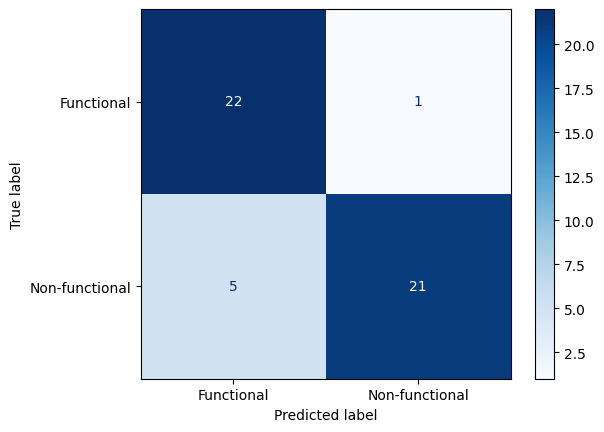

In [45]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_true=req_eval_sample.Category,
                                        y_pred=req_eval_sample.Predicted_category,
                                        cmap='Blues');

In [46]:
print(classification_report(y_true=req_eval_sample.Category, y_pred=req_eval_sample.Predicted_category))

                precision    recall  f1-score   support

    Functional       0.81      0.96      0.88        23
Non-functional       0.95      0.81      0.88        26

      accuracy                           0.88        49
     macro avg       0.88      0.88      0.88        49
  weighted avg       0.89      0.88      0.88        49



Let's examine where the LLM made mistakes:

In [47]:
for error in errors:
  print(error['Requirement'])
  print(error['Predicted_category'])
  print('-'*70)

The product shall provide Error Tracking Services.The product shall help the System Administrators and DBAs to resolve transaction errors 99% of the time.
Functional
Non-functional
----------------------------------------------------------------------


In [48]:
req_eval_sample['correct_cls'] = req_type_match
display(req_eval_sample.loc[~req_eval_sample.correct_cls, ['Requirement','Category','Predicted_category']])

,Requirement,Category,Predicted_category
2,Users shall be able to reach the add drop ...,Non-functional,Functional
11,New branches/complexes/districts/regions and r...,Non-functional,Functional
17,Admin Login Account Security GIST: Security of...,Non-functional,Functional
29,The product shall create an exception log of p...,Non-functional,Functional
40,Only adjusters with a supervisor role can upda...,Non-functional,Functional
46,Prominent search feature DESC: The search feat...,Functional,Non-functional


Save the results in a csv file:

In [49]:
fname = "sample_requirements_labelled.csv"
req_eval_sample.to_csv(fname, index=False)
files.download(fname)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>